In [115]:
import numpy as np
import matplotlib.pyplot as plt
from pwr_two_point_plant_v2 import *

## Basic interaction

In [116]:
plant = Plant()
print(f"{plant.n} states, {plant.m} inputs")

53 states, 8 inputs


### getting steady state (trim)

In [117]:
x0, u0, residual = trim(plant, 1.0)      # 1.0 = 100 % power
print(f"residual: {residual:.2e}")

sig = plant.signals(x0)
for k in ("Pn", "DI", "Tavg", "Thot", "Tcold", "ps"):
    print(f"  {k:6s} {sig[k]:10.4f}")

residual: 5.29e-13
  Pn         1.0000
  DI         0.0000
  Tavg     315.9221
  Thot     327.2997
  Tcold    296.9595
  ps         7.2800


## Simple simulation

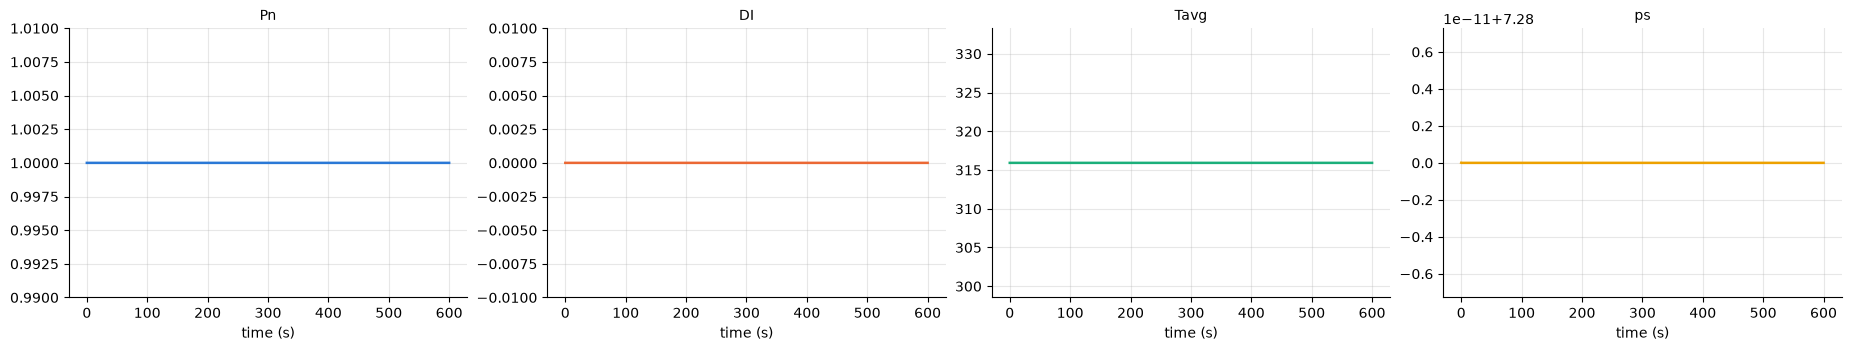

In [118]:
res = ClosedLoop(plant, [], x0=x0, u0=u0).run(600)     # 600 seconds

axs = res.plot(["Pn", "DI", "Tavg", "ps"], subplots=True)
axs[0].set_ylim(0.99, 1.01)
axs[1].set_ylim(-0.01, 0.01)
plt.show()


In [119]:
res.df[["t", "Pn", "DI", "ps", "u_utg"]].tail(3) # tail gets the last 3 entries of the dataframe. Opposite to .head()


,t,Pn,DI,ps,u_utg
1497,599.199466,1.0,-2.220446e-16,7.28,0.999631
1498,599.599733,1.0,-2.220446e-16,7.28,0.999631
1499,600.000000,1.0,-3.330669e-16,7.28,0.999631


In [ ]:
print(U_NAMES)          # ['vrod_M', 'vrod_AO', 'utg', 'iheat', 'mdot_spr', 'Pdem', 'T_fw']
print(IU["utg"])        # 2        <- 'utg' is the third slot
print(u0)               # [0.  0.  0.99963  0.  0.  0.99996  232.2]
print(u0[IU["utg"]])    # 0.99963  <- the valve, at the trim point


## Building a closed loop with step input

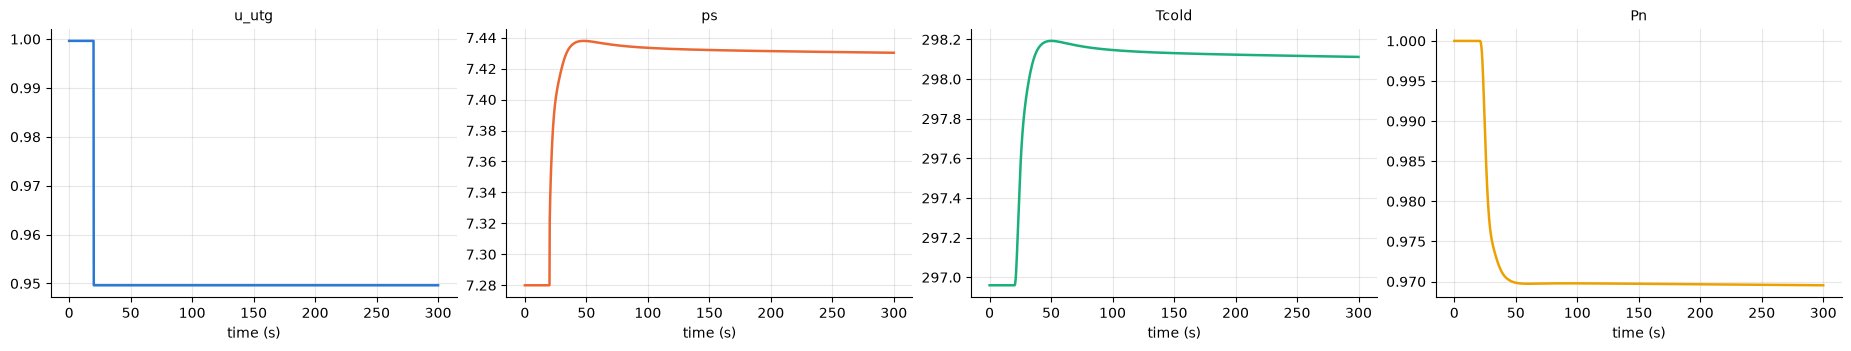

In [120]:
base = u0[IU["utg"]]      # the trimmed valve position, 0.99963 (not 1.0)

loop = ClosedLoop(
    plant,
    [Manual("utg", lambda t, sig: base + (-0.05 if t > 20 else 0))],
    x0=x0, u0=u0,
)
res = loop.run(300)

res.plot(["u_utg", "ps", "Tcold", "Pn"], subplots=True)
plt.show()


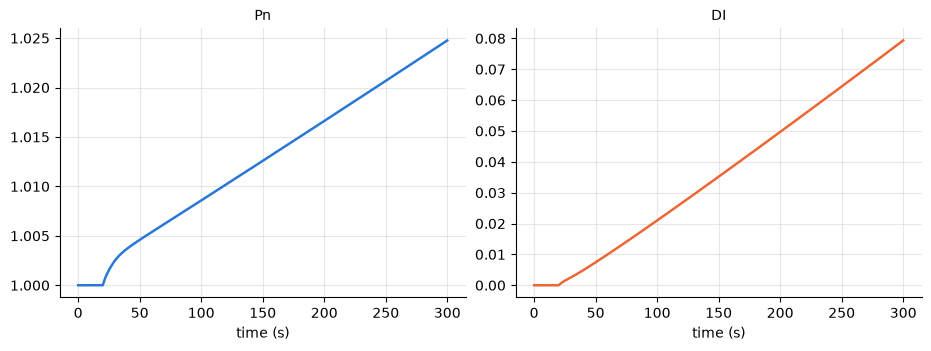

In [121]:
loop = ClosedLoop(
    plant,
    [Manual("vrod_M", lambda t, sig: 5.0 if t > 20 else 0.0)],
    x0=x0, u0=u0,
)
res = loop.run(300)
res.plot(["Pn", "DI"], subplots=True)
plt.show()


In [122]:
class HoldPower(Controller):
    name = "hold_power"

    def update(self, t, sig, xc, u, ctx):
        error = ctx.demand(t) - sig["Pn"]              # where we want - where we are. 
        # ctx.demand(t) returns the value of the demand at time t
        # sig["Pn"] -> plant.signals(x)["Pn"]

        speed = float(np.clip(3000.0 * error, -72.0, 72.0))
        u[IU["vrod_AO"]]  += speed                      # note +=
        u[IU["vrod_AO"]] += speed
        return EMPTY                                   # no internal state


In [123]:
loop = ClosedLoop(
    plant,
    [HoldPower(),
     Manual("utg", lambda t, sig: base + (0.05 if t > 20 else 0))],
    demand=lambda t: 1.0,          # hold 100 % power
    x0=x0, u0=u0,
)
res = loop.run(300)


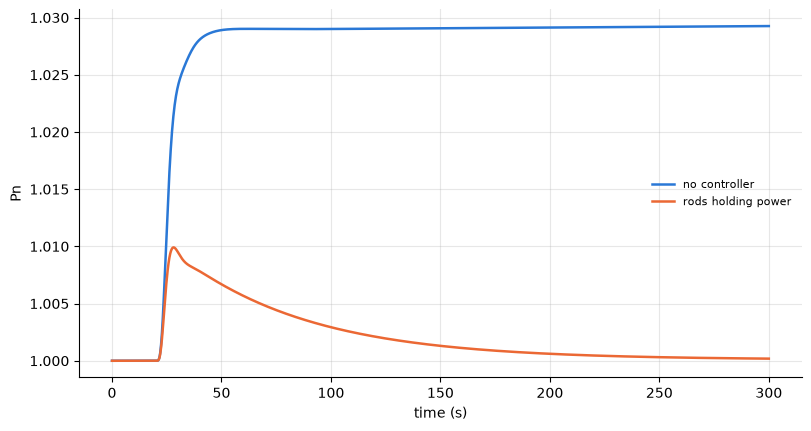

In [124]:
ol = ClosedLoop(plant,
                [Manual("utg", lambda t, sig: base + (0.05 if t > 20 else 0))],
                x0=x0, u0=u0).run(300)

ax = ol.plot(["Pn"], label="no controller")
res.plot(["Pn"], ax=ax, label="rods holding power")
ax.set_ylabel("Pn")
plt.show()


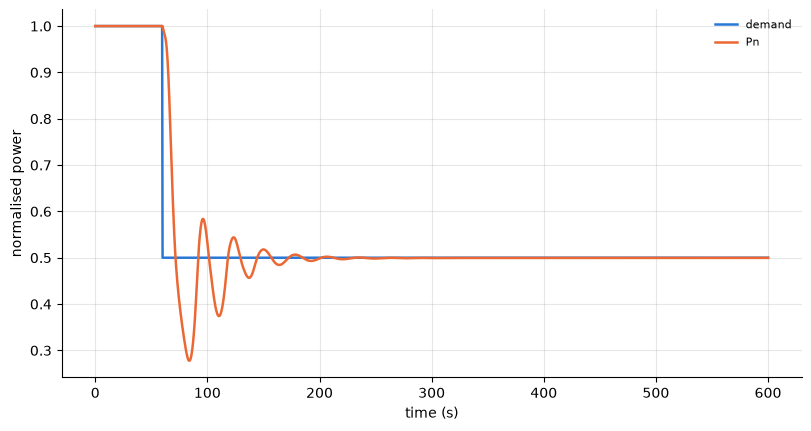

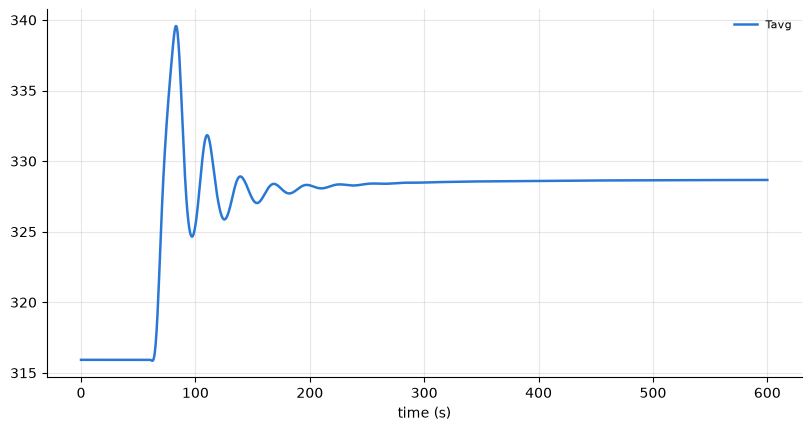

In [125]:
demand = step(1.0, 0.5, t_step=60.0)      # drop to 90 % at t = 60 s

loop = ClosedLoop(plant,
                  [GridDemand(), TurbineSpeedPI(), HoldPower()],
                  demand=demand, x0=x0, u0=u0)


res = loop.run(600)

ax = res.plot(["demand", "Pn"])
ax.set_ylabel("normalised power")

ax1 = res.plot(["Tavg"])
plt.show()


## Creating controllers

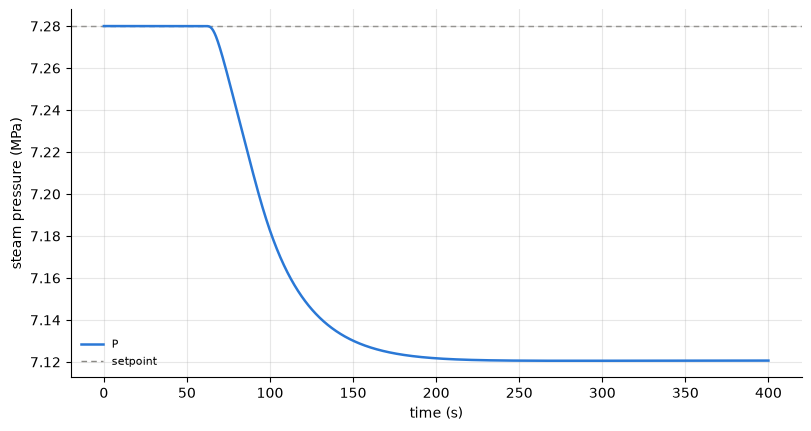

In [126]:
class ValveP(Controller):
    name = "valve_p"

    def __init__(self, kp=0.5):
        self.kp = kp

    def update(self, t, sig, xc, u, ctx):
        error = sig["ps"] - ctx.sig0["ps"]             # see the sign note below
        u[IU["utg"]] = ctx.u0[IU["utg"]] + self.kp * error
        return EMPTY

demand = step(1.0, 0.9, t_step=60.0)
res_p = ClosedLoop(plant, [GridDemand(), HoldPower(), ValveP()],
                   demand=demand, x0=x0, u0=u0).run(400)

ax = res_p.plot(["ps"], label="P")
res_p.setpoint(ax, plant.p.ps0, "setpoint")
ax.set_ylabel("steam pressure (MPa)")
plt.show()


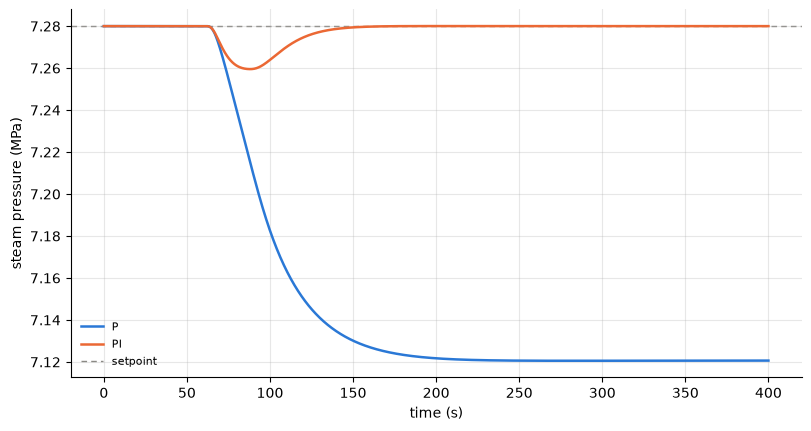

In [127]:
class ValvePI(Controller):
    name   = "valve_pi"
    states = ("I",)                    # one internal state, named I

    def __init__(self, kp=0.5, ki=0.12):
        self.kp, self.ki = kp, ki

    def update(self, t, sig, xc, u, ctx):
        error = sig["ps"] - ctx.sig0["ps"]
        u[IU["utg"]] = ctx.u0[IU["utg"]] + self.kp*error + self.ki*xc[0]
        return np.array([error])       # d(I)/dt = error

res_pi = ClosedLoop(plant, [GridDemand(), HoldPower(), ValvePI()],
                    demand=demand, x0=x0, u0=u0).run(400)

ax = res_p.plot(["ps"], label="P")
res_pi.plot(["ps"], ax=ax, label="PI")
res_p.setpoint(ax, plant.p.ps0, "setpoint")
ax.set_ylabel("steam pressure (MPa)")
plt.show()



In [128]:
class ValvePID(Controller):
    name   = "valve_pid"
    states = ("I", "ps_filt")

    def __init__(self, kp=0.5, ki=0.12, kd=0.5, tau_f=1.0):
        self.kp, self.ki, self.kd, self.tau_f = kp, ki, kd, tau_f

    def initialize(self, ctx):
        return np.array([0.0, ctx.sig0["ps"]])        # start the filter at ps

    def update(self, t, sig, xc, u, ctx):
        error = sig["ps"] - ctx.sig0["ps"]
        d_ps  = (sig["ps"] - xc[1]) / self.tau_f      # filtered derivative
        u[IU["utg"]] = (ctx.u0[IU["utg"]] + self.kp*error
                        + self.ki*xc[0] + self.kd*d_ps)
        return np.array([error, d_ps])


## Actual Load following

<Axes: xlabel='time (h)'>

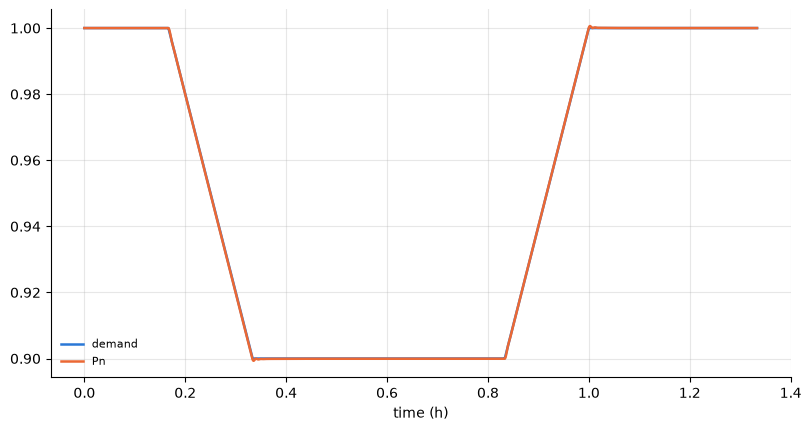

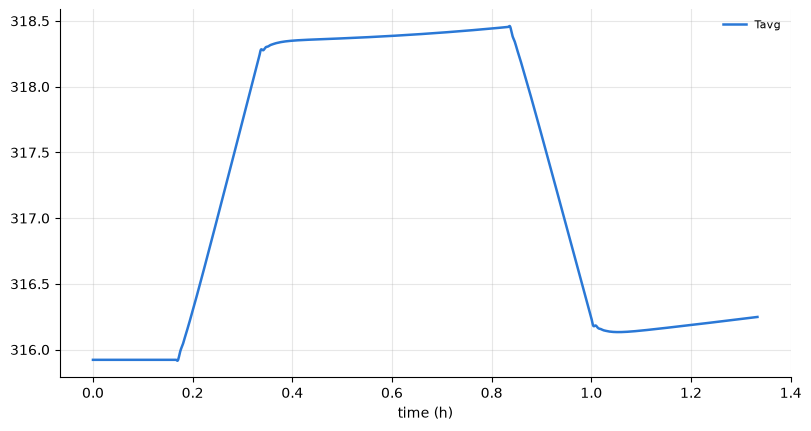

In [129]:
demand = ramp(start=1.0,        # begin at full power
              target=0.9,       # go to 90 %
              t_start=600.0,    # hold full power for the first 10 minutes
              ramp_time=600.0,  # take 10 minutes to get there
              hold=1800.0)      # sit at 90 % for 30 minutes, then ramp back

loop = ClosedLoop(plant,
                  [GridDemand(),      # tell the turbine what the grid wants
                   TurbineSpeedPI(),  # governor holds the shaft at 60 Hz
                   HoldPower()],      # rods bring reactor power to demand
                  demand=demand, x0=x0, u0=u0)

res = loop.run(4800, n_out=1600, max_step=2.0)      # 80 minutes

res.plot(["demand", "Pn"])
res.plot(["Tavg"])

In [130]:
prog = tavg_program(plant)
print(prog(1.0), prog(0.5), prog(0.0))


315.92263849197593 301.99131924598794 288.06


<Axes: xlabel='time (h)'>

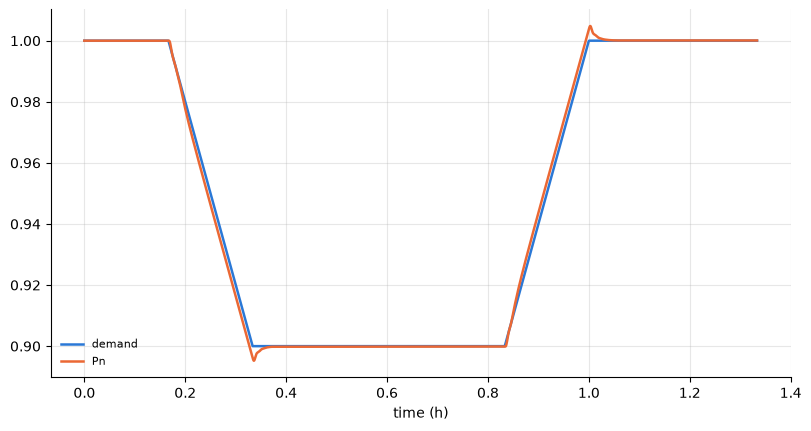

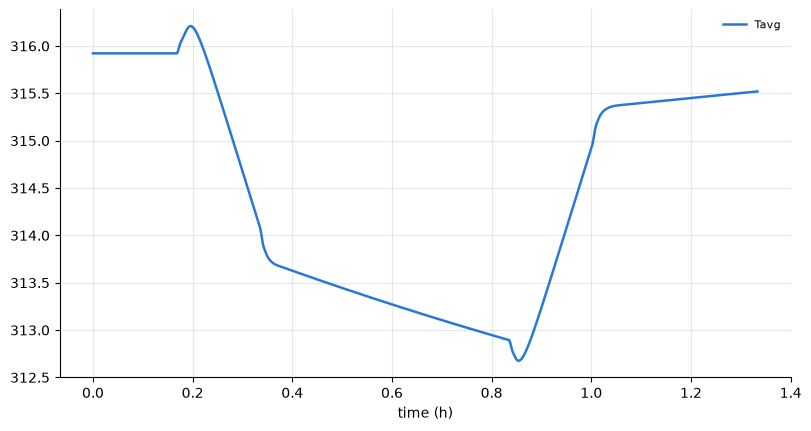

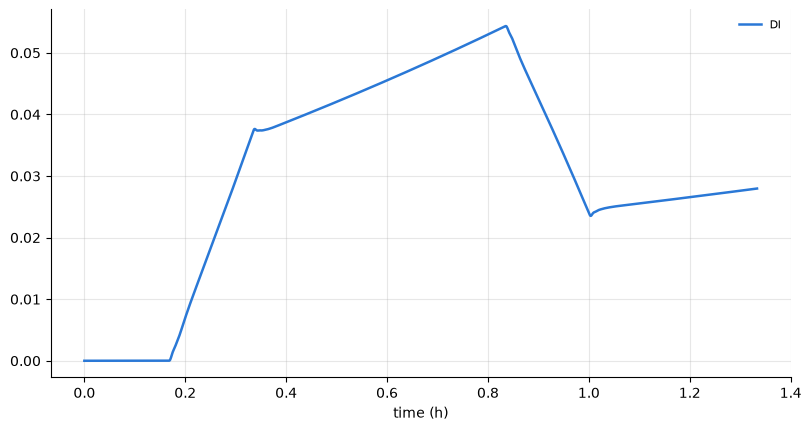

In [131]:
loop = ClosedLoop(plant,
                  [GridDemand(),       # grid takes less
                   TurbineSpeedPI(),   # governor opens/closes the valve on SPEED
                   RodsOnTavg()],      # rods hold Tavg on PROGRAM
                  demand=demand, x0=x0, u0=u0)
res = loop.run(4800, n_out=1600, max_step=2.0)
res.plot(["demand", "Pn"])
res.plot(["Tavg"])
res.plot(["DI"])

<Axes: xlabel='time (h)'>

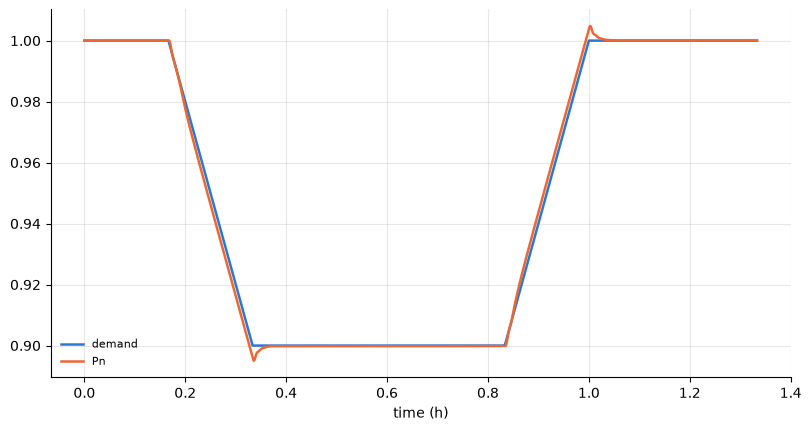

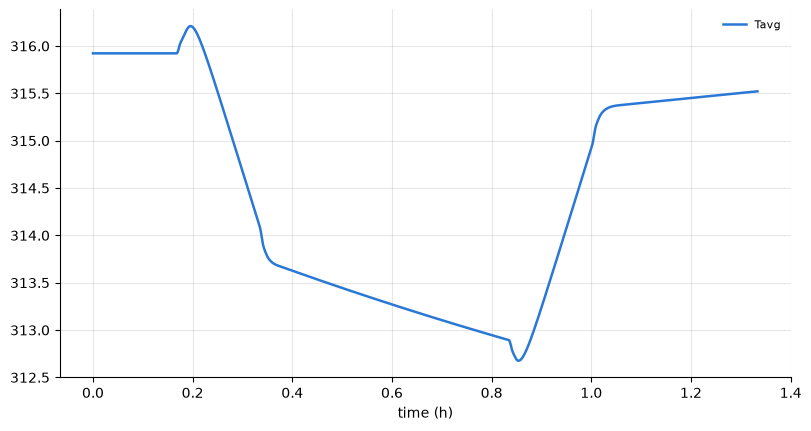

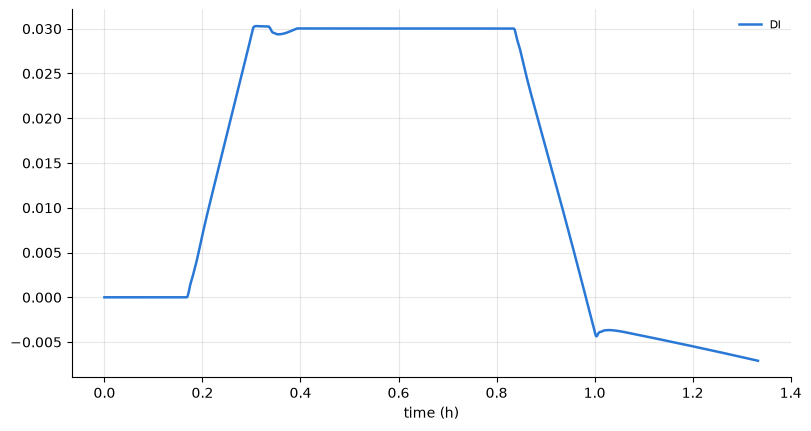

In [132]:
demand = ramp(start=1.0, target=0.9, t_start=600.0,
              ramp_time=600.0, hold=1800.0)

loop = ClosedLoop(plant,
                  [GridDemand(),               # the grid's load profile
                   TurbineSpeedPI(),           # SPEED  -> valve
                   RodsOnTavg(),               # Tavg   -> both rods together
                   AxialOffsetBand(band=0.03)],# DI     -> the rods in opposition
                  demand=demand, x0=x0, u0=u0)

res = loop.run(4800, n_out=1600, max_step=2.0)

res.plot(["demand", "Pn"])
res.plot(["Tavg"])
res.plot(["DI"])


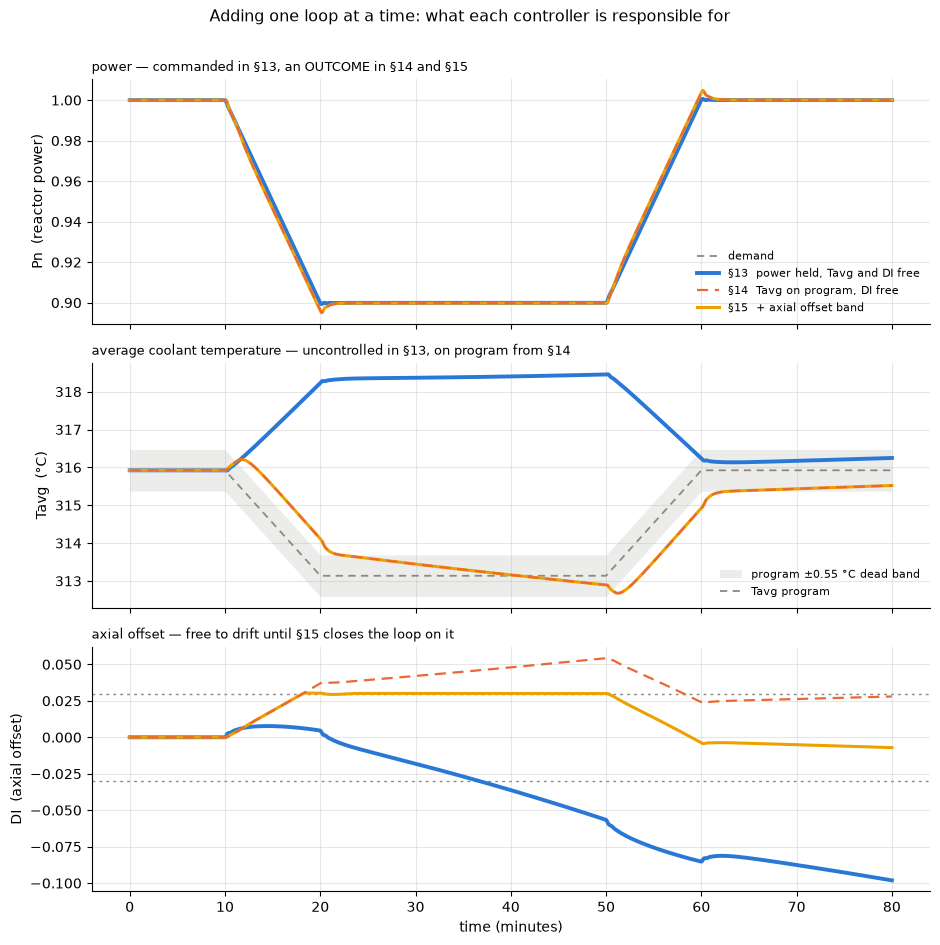

In [133]:
import matplotlib.pyplot as plt

prog = tavg_program(plant)

# §14 coincides with §13 on DI AND with §15 on Pn and Tavg, so it is drawn
# LAST, thin and dashed, on top of both.  Colour alone would hide one of them.
#            label                        controllers        colour  style  lw  zorder
CASES = [("§13  power held, Tavg and DI free",
          [GridDemand(), TurbineSpeedPI(), HoldPower()],
          Result.COLORS[0], "-", 2.8, 2),
         ("§14  Tavg on program, DI free",
          [GridDemand(), TurbineSpeedPI(), RodsOnTavg()],
          Result.COLORS[1], (0, (5, 3)), 1.6, 4),
         ("§15  + axial offset band",
          [GridDemand(), TurbineSpeedPI(), RodsOnTavg(), AxialOffsetBand(band=0.03)],
          Result.COLORS[3], "-", 2.2, 3)]

runs = {lab: ClosedLoop(plant, c, demand=demand, x0=x0, u0=u0)
                 .run(4800, n_out=1600, max_step=2.0).df
        for lab, c, *_ in CASES}

fig, axs = plt.subplots(3, 1, figsize=(9.5, 9.6), sharex=True)
d0 = runs[CASES[0][0]]
t0 = d0["t"] / 60.0
tgt = np.array([prog(v) for v in d0["demand"]])

axs[0].plot(t0, d0["demand"], color="#8a8984", lw=1.3, ls=(0, (4, 3)), label="demand")
axs[1].fill_between(t0, tgt - 0.55, tgt + 0.55, color="#8a8984", alpha=0.16, lw=0,
                    label="program ±0.55 °C dead band")        # <- the dead band
axs[1].plot(t0, tgt, color="#8a8984", lw=1.3, ls=(0, (4, 3)), label="Tavg program")
for y in (0.03, -0.03):                                        # <- the AO band
    axs[2].axhline(y, color="#8a8984", lw=1.0, ls=(0, (2, 3)), zorder=0)

for lab, _, col, ls, lw, z in CASES:
    d = runs[lab]
    axs[0].plot(d["t"]/60.0, d["Pn"],   color=col, lw=lw, ls=ls, zorder=z, label=lab)
    axs[1].plot(d["t"]/60.0, d["Tavg"], color=col, lw=lw, ls=ls, zorder=z)
    axs[2].plot(d["t"]/60.0, d["DI"],   color=col, lw=lw, ls=ls, zorder=z)

axs[0].set_title("power — commanded in §13, an OUTCOME in §14 and §15",
                 fontsize=9.5, loc="left")
axs[1].set_title("average coolant temperature — uncontrolled in §13, on program from §14",
                 fontsize=9.5, loc="left")
axs[2].set_title("axial offset — free to drift until §15 closes the loop on it",
                 fontsize=9.5, loc="left")
for ax, yl in zip(axs, ("Pn  (reactor power)", "Tavg  (°C)", "DI  (axial offset)")):
    ax.set_ylabel(yl); ax.grid(alpha=.3)
    ax.spines[["top", "right"]].set_visible(False)
axs[2].set_xlabel("time (minutes)")
axs[0].legend(fontsize=8, frameon=False, loc="lower right")
axs[1].legend(fontsize=8, frameon=False, loc="lower right")
fig.suptitle("Adding one loop at a time: what each controller is responsible for",
             fontsize=11.5)
fig.tight_layout(rect=[0, 0, 1, 0.975])
plt.show()


### extending over 24 hours

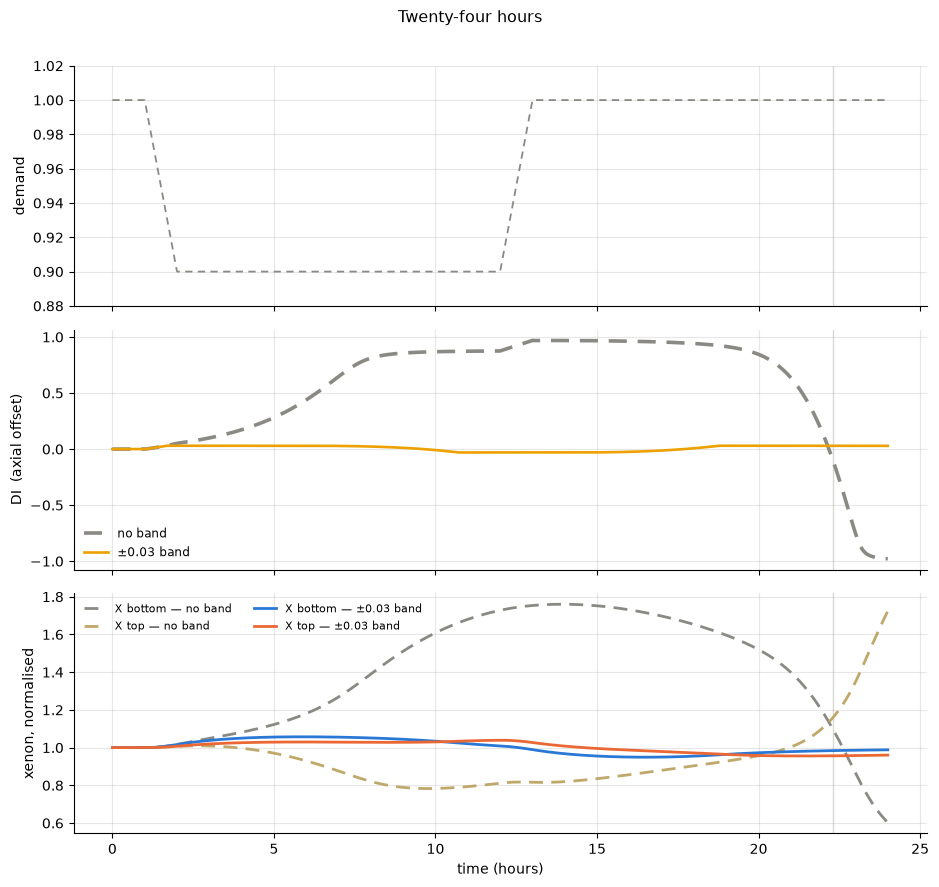

In [134]:
demand = ramp(start=1.0, target=0.9, t_start=3600.0,
              ramp_time=3600.0, hold=36000.0)
res = loop.run(24 * 3600, n_out=2000, max_step=5.0)


runs24 = {}
for lab, extra in (("no band", []), ("±0.03 band", [AxialOffsetBand(band=0.03)])):
    runs24[lab] = ClosedLoop(plant, [GridDemand(), TurbineSpeedPI(), RodsOnTavg()] + extra,
                             demand=demand, x0=x0, u0=u0
                             ).run(24*3600, n_out=2000, max_step=5.0).df

fig, axs = plt.subplots(3, 1, figsize=(9.5, 9.0), sharex=True)
h = runs24["no band"]["t"] / 3600.0

axs[0].plot(h, runs24["no band"]["demand"], color="#8a8984", lw=1.3, ls=(0, (4, 3)))
axs[0].set_ylabel("demand"); axs[0].set_ylim(0.88, 1.02)

axs[1].plot(h, runs24["no band"]["DI"],    color="#8a8984", lw=2.6, ls=(0, (5, 3)),
            label="no band")
axs[1].plot(h, runs24["±0.03 band"]["DI"], color=Result.COLORS[3], lw=1.9,
            label="±0.03 band")
axs[1].set_ylabel("DI  (axial offset)")
axs[1].legend(fontsize=8.5, frameon=False, loc="lower left")

# the two halves' xenon is what drives the panel above
for lab, (c_bot, c_top, ls) in (("no band",    ("#8a8984", "#c0a86a", (0, (5, 3)))),
                                ("±0.03 band", (Result.COLORS[0], Result.COLORS[1], "-"))):
    d = runs24[lab]
    axs[2].plot(h, d["X_h1"], color=c_bot, lw=2.0, ls=ls, label=f"X bottom — {lab}")
    axs[2].plot(h, d["X_h2"], color=c_top, lw=2.0, ls=ls, label=f"X top — {lab}")
axs[2].set_ylabel("xenon, normalised"); axs[2].set_xlabel("time (hours)")
axs[2].legend(fontsize=8, frameon=False, ncol=2, loc="upper left")

for ax in axs:
    ax.axvline(22.3, color="#d8d7d2", lw=1.0, zorder=0)        # where they cross
    ax.grid(alpha=.3); ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Twenty-four hours", fontsize=11.5)
fig.tight_layout(rect=[0, 0, 1, 0.975])
plt.show()


In [135]:
import numpy as np
from scipy.optimize import lsq_linear
from scipy.signal import cont2discrete

class SimpleMPC(Controller):
    name = "simple_mpc"
    Ts   = 5.0                      # MPC must be SAMPLED, never continuous

    def __init__(self, N=20, r=1e-5, v_max=72.0, preview=False):
        self.N, self.r, self.v_max, self.preview = N, r, v_max, preview

    def initialize(self, ctx):
        # 1. a linear prediction model, from the plant itself
        A, B, C, D, S = linearize(ctx.plant, ctx.x0, ctx.u0)
        self.S = S
        b = (B[:, IU["vrod_M"]] + B[:, IU["vrod_AO"]]).reshape(-1, 1)   # common mode
        c = C[[OUTPUT_NAMES.index("Pn")], :]
        Ad, Bd, Cd, _, _ = cont2discrete((A, b, c, 0), self.Ts, method="zoh")

        # 2. a condensed prediction:  y = Psi @ z  +  Theta @ v
        N = self.N
        self.Psi = np.vstack([Cd @ np.linalg.matrix_power(Ad, k + 1)
                              for k in range(N)])
        self.Theta = np.zeros((N, N))
        for k in range(N):
            for j in range(k + 1):                       # lower triangular:
                self.Theta[k, j] = (Cd @ np.linalg.matrix_power(Ad, k - j)
                                    @ Bd).item()         # causality
        # stack tracking rows on sqrt(r)*I so ONE least squares does both jobs
        self.M = np.vstack([self.Theta, np.sqrt(self.r) * np.eye(N)])
        return EMPTY

    def update(self, t, sig, xc, u, ctx):
        z = (ctx.x - ctx.x0) / self.S                    # scaled deviation state
        if self.preview:          # MPC may read the FUTURE of the profile
            ref = np.array([ctx.demand(t + (k + 1) * self.Ts) - ctx.sig0["Pn"]
                            for k in range(self.N)])
        else:
            ref = np.full(self.N, ctx.demand(t) - ctx.sig0["Pn"])
        rhs = np.concatenate([ref - self.Psi @ z, np.zeros(self.N)])
        # 3. a box-constrained least squares, re-solved every Ts seconds
        sol = lsq_linear(self.M, rhs, bounds=(-self.v_max, self.v_max),
                         lsmr_tol="auto", max_iter=30)
        v = float(sol.x[0])                              # receding horizon
        u[IU["vrod_M"]]  += v
        u[IU["vrod_AO"]] += v
        return EMPTY


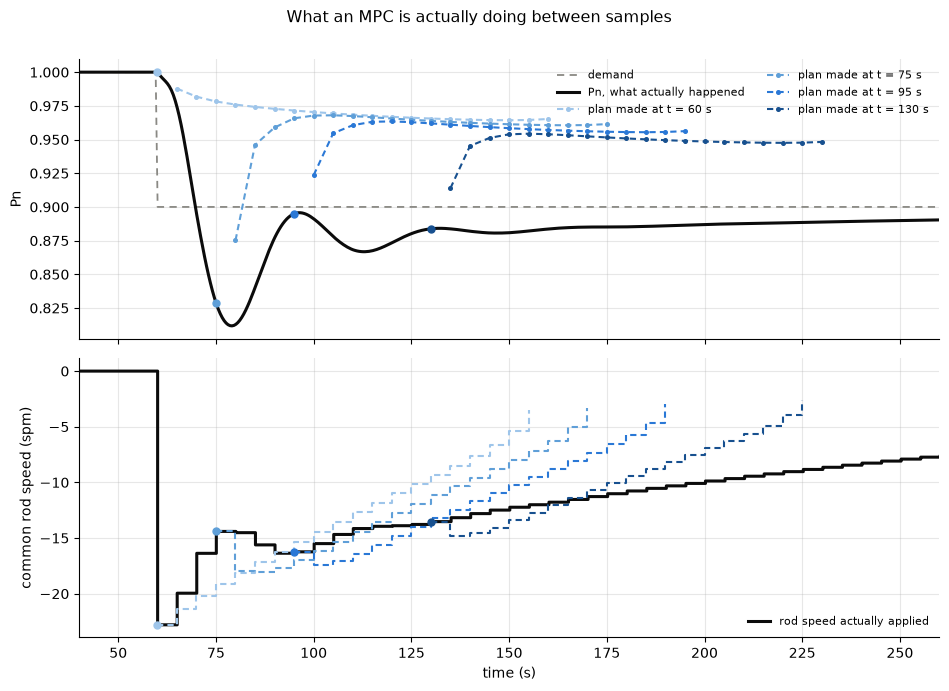

In [136]:
class RecordingMPC(SimpleMPC):
    """Same controller, but keeps the plan it throws away at each sample."""
    def initialize(self, ctx):
        self.log = []
        return super().initialize(ctx)

    def update(self, t, sig, xc, u, ctx):
        z   = (ctx.x - ctx.x0) / self.S
        ref = np.full(self.N, ctx.demand(t) - ctx.sig0["Pn"])
        rhs = np.concatenate([ref - self.Psi @ z, np.zeros(self.N)])
        sol = lsq_linear(self.M, rhs, bounds=(-self.v_max, self.v_max),
                         lsmr_tol="auto", max_iter=30)
        y_pred = self.Psi @ z + self.Theta @ sol.x + ctx.sig0["Pn"]
        self.log.append((t, sol.x.copy(), y_pred))      # <- the whole plan
        v = float(sol.x[0])
        u[IU["vrod_M"]] += v; u[IU["vrod_AO"]] += v
        return EMPTY

rec = RecordingMPC(N=20, r=1e-5)
d = ClosedLoop(plant, [GridDemand(), TurbineSpeedPI(), rec],
               demand=step(1.0, 0.9, t_step=60.0),
               x0=x0, u0=u0).run(400, n_out=800, max_step=2.0).df

SHOW = [60.0, 75.0, 95.0, 130.0]                        # four sample instants
FAN  = ["#9ec5ea", "#5f9fd8", "#2a78d6", "#17508f"]     # pale -> dark, in time order
plans = [L for L in rec.log if L[0] in SHOW]

fig, axs = plt.subplots(2, 1, figsize=(9.5, 7.0), sharex=True)
axs[0].plot(d["t"], d["demand"], color="#8a8984", lw=1.3, ls=(0, (4, 3)), label="demand")
axs[0].plot(d["t"], d["Pn"], color="#0b0b0b", lw=2.2, label="Pn, what actually happened")
axs[1].step(d["t"], d["u_vrod_M"], color="#0b0b0b", lw=2.2, where="post",
            label="rod speed actually applied")

for (t_k, v_plan, y_pred), col in zip(plans, FAN):
    t_y = t_k + np.arange(1, rec.N + 1) * rec.Ts        # predicted outputs
    t_u = t_k + np.arange(0, rec.N) * rec.Ts            # planned inputs
    axs[0].plot(t_y, y_pred, color=col, lw=1.5, ls=(0, (3, 2)), marker="o", ms=2.6,
                label=f"plan made at t = {t_k:.0f} s")
    axs[1].step(t_u, v_plan, color=col, lw=1.5, ls=(0, (3, 2)), where="post")
    # the filled dot is the ONLY move that is ever applied
    axs[0].plot([t_k], [np.interp(t_k, d["t"], d["Pn"])], "o", ms=5, color=col, zorder=5)
    axs[1].plot([t_k], [v_plan[0]], "o", ms=5, color=col, zorder=5)

axs[0].set_ylabel("Pn"); axs[0].set_xlim(40, 260)
axs[1].set_ylabel("common rod speed (spm)"); axs[1].set_xlabel("time (s)")
axs[0].legend(fontsize=8, frameon=False, ncol=2, loc="upper right")
axs[1].legend(fontsize=8, frameon=False, loc="lower right")
for ax in axs:
    ax.grid(alpha=.3); ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("What an MPC is actually doing between samples", fontsize=11.5)
fig.tight_layout(rect=[0, 0, 1, 0.975])
plt.show()


In [137]:
# ---------------------------------------------------------------------------
#  The same loop, written from scratch
# ---------------------------------------------------------------------------
W0 = plant.p.w_tur0

class MyGovernor(Controller):
    """Speed -> governor valve, PI with back-calculation anti-windup.

    Sign: error is (setpoint - measurement). Running FAST gives a negative
    error, which lowers the valve command. Get this backwards and the run
    grinds rather than raising an error.
    """
    name   = "my_governor"
    states = ("I",)                      # declare the integrator

    def __init__(self, kp, ki, lo=0.0, hi=1.5, t_track=10.0):
        """
        lo, hi   valve travel limits on `utg`.  0.0 = shut, 1.5 = wide open.
                 Trim sits at ~0.9996, so `hi` leaves headroom to open further.
                 np.clip below enforces them; without it the controller could
                 command a valve position that does not physically exist.

        t_track  anti-windup tracking time constant, seconds.  While the valve
                 is clipped the error persists -- the controller cannot fix it --
                 so a plain integrator keeps accumulating and must later be
                 unwound before the output leaves the stop.  Back-calculation
                 feeds the clipped-off amount back in:

                     dI/dt = e + (cmd - raw) / t_track

                 Unclipped, cmd == raw and that term is exactly zero, so this is
                 an ordinary PI.  Clipped, it pulls the integrator back toward
                 what the actuator can actually deliver; smaller t_track pulls
                 harder.  Rule of thumb: order of the loop's dominant time
                 constant, which here is tau_hp = 10 s.

                 NOTE: in this plant the valve has enough range that realistic
                 manoeuvres never reach a stop, so this term rarely fires.  It
                 is insurance, not a tuning knob.
        """
        self.kp, self.ki, self.lo, self.hi, self.t_track = kp, ki, lo, hi, t_track

    def initialize(self, ctx):
        self.base = float(ctx.u0[IU["utg"]])    # valve position at trim
        return np.zeros(1)                      # I(0) = 0

    def update(self, t, sig, xc, u, ctx):
        e   = W0 - sig["w_tur"]                 # + when running slow
        raw = self.base + self.kp * e + self.ki * xc[0]
        cmd = float(np.clip(raw, self.lo, self.hi))
        u[IU["utg"]] = cmd
        return np.array([e + (cmd - raw) / self.t_track])   # anti-windup




In [138]:
# tuning a PI controller

# ============================================================================
#  Tuning a governor: 2-D gain sweep, built-in and hand-rolled
#  Assumes:  from pwr_two_point_plant_v2 import *   (plus numpy as np, plt)
# ============================================================================
plant = Plant()
x0, u0, _ = trim(plant, 1.0)
reject = step(1.0, 0.9, t_step=20.0)          # grid sheds 10 % at t = 20 s



def score(ctl, t_end=200.0):
    """Run one load rejection; return cost and the trajectory."""
    d = ClosedLoop(plant, [GridDemand(), ctl], demand=reject,
                   x0=x0, u0=u0).run(t_end, n_out=300, max_step=2.0).df
    e = d["w_tur"].to_numpy() - W0              # speed error, Hz, over the run


    sat = bool((d["u_utg"] <= 1e-9).any() or (d["u_utg"] >= 1.4999).any())


    return dict(peak=np.abs(e).max(),
                iae=float(np.trapezoid(np.abs(e), d["t"])),
                sat=sat, df=d)


def sweep(make, KP, KI):
    """make(kp, ki) -> controller.  Returns IAE grid, NaN where valve saturates."""
    J = np.full((len(KI), len(KP)), np.nan)
    for i, ki in enumerate(KI):
        for j, kp in enumerate(KP):
            s = score(make(KP[j], KI[i]))
            J[i, j] = np.nan if s["sat"] else s["iae"]
    return J


def report(J, KP, KI, label):
    i, j = np.unravel_index(np.nanargmin(J), J.shape)
    print(f"{label}: best kp = {KP[j]:g}, ki = {KI[i]:g}  (IAE {J[i, j]:.3f});  "
          f"{np.isnan(J).sum()}/{J.size} saturated")
    return KP[j], KI[i]


def heatmap(ax, J, KP, KI, title, ylab=True):
    """Single-hue sequential: DARK = low IAE = good. Grey = valve saturated."""
    cmap = plt.get_cmap("Blues_r").copy()
    cmap.set_bad("#e8e6e1")                               # NaN = saturated
    im = ax.imshow(J, origin="lower", cmap=cmap, aspect="auto")
    ax.set_xticks(range(len(KP)), [f"{v:g}" for v in KP])
    ax.set_yticks(range(len(KI)), [f"{v:g}" for v in KI])
    ax.set_xlabel("$k_p$"); ax.set_title(title, fontsize=10)
    ax.set_ylabel("$k_i$" if ylab else "")
    i, j = np.unravel_index(np.nanargmin(J), J.shape)
    ax.scatter([j], [i], s=140, facecolors="none", edgecolors="#1a1a1a", lw=1.8)
    ax.annotate("best", (j, i), xytext=(0, 12), textcoords="offset points",
                ha="center", fontsize=8.5, color="#1a1a1a")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    return im




In [139]:
# ---------------------------------------------------------------------------
#  Sweep the shipped TurbineSpeedPI
# ---------------------------------------------------------------------------
KP = np.array([0.05, 0.1, 0.2, 0.333, 0.6])     # 0.333 = 5 % droop
KI = np.array([1e-3, 3e-3, 1e-2, 3e-2])

J_builtin = sweep(lambda kp, ki: TurbineSpeedPI(kp=kp, ki=ki), KP, KI)
kp_b, ki_b = report(J_builtin, KP, KI, "TurbineSpeedPI ")


J_mine = sweep(lambda kp, ki: MyGovernor(kp, ki), KP, KI)
kp_m, ki_m = report(J_mine, KP, KI, "MyGovernor     ")

TurbineSpeedPI : best kp = 0.6, ki = 0.01  (IAE 15.709);  4/20 saturated
MyGovernor     : best kp = 0.6, ki = 0.01  (IAE 15.709);  4/20 saturated


sweeps identical: True  (they must be — same law, unsaturated)


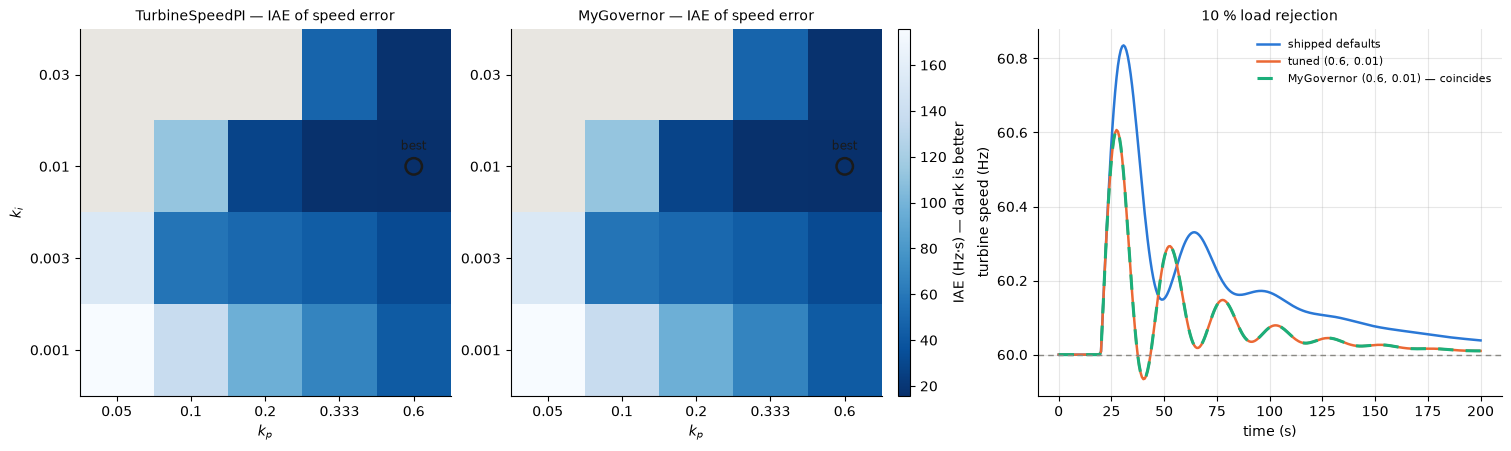

In [140]:
# ---------------------------------------------------------------------------
#  Look at them
# ---------------------------------------------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4), constrained_layout=True,
                        gridspec_kw={"width_ratios": [1, 1, 1.25]})
im = heatmap(axs[0], J_builtin, KP, KI, "TurbineSpeedPI — IAE of speed error")
heatmap(axs[1], J_mine, KP, KI, "MyGovernor — IAE of speed error", ylab=False)
fig.colorbar(im, ax=axs[:2], label="IAE (Hz·s) — dark is better", pad=0.02, fraction=0.045, aspect=30)

# the two sweeps should agree wherever the valve never clips: same control law
agree = np.allclose(J_builtin, J_mine, equal_nan=True)
print(f"sweeps identical: {agree}  (they must be — same law, unsaturated)")

runs = [("shipped defaults", TurbineSpeedPI(), Result.COLORS[0], "-", 1.8),
        (f"tuned ({kp_b:g}, {ki_b:g})", TurbineSpeedPI(kp=kp_b, ki=ki_b),
         Result.COLORS[1], "-", 1.8),
        (f"MyGovernor ({kp_m:g}, {ki_m:g}) — coincides",
         MyGovernor(kp_m, ki_m), Result.COLORS[2], (0, (5, 4)), 2.2)]
for lbl, ctl, c, ls, lw in runs:
    d = score(ctl)["df"]
    axs[2].plot(d["t"], d["w_tur"], color=c, lw=lw, ls=ls, label=lbl)
axs[2].axhline(W0, color="#8a8984", lw=1, ls=(0, (4, 3)))
axs[2].set_xlabel("time (s)"); axs[2].set_ylabel("turbine speed (Hz)")
axs[2].set_title("10 % load rejection", fontsize=10)
axs[2].legend(fontsize=8, frameon=False); axs[2].grid(alpha=.3)
for s in ("top", "right"):
    axs[2].spines[s].set_visible(False)
plt.show()